# Reto Text-based Personality Computing: predicindo Big-5 a partir de Reddit
**Equipo:** `VAIA` · **Integrantes:** _Lucas Amado Oseira, María Lestón Geada, Iria Varela Palmás_

Obxectivo: predicir para cada usuario/a de test as 5 dimensións Big Five (0–100) a partir das súas publicacións. Métrica: **RMSE medio das 5 dimensións**.

Estrutura do notebook:
1. Configuración e carga de datos
2. Exploración
3. Preparación a nivel de usuario/a
4. Baseline (media do train)
5. Modelo 1: TF-IDF + Ridge
6. Modelo 2: embeddings SBERT + Ridge
7. Comparación e xeración dos CSV de envío

In [4]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
import zipfile, os
from google.colab import drive

drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/material.zip"

TEAM = "VAIA"          # <- cambiar
DATA = "/content/material"           # carpeta cos CSV
TRAITS = ["agreeableness","openness","conscientiousness","extraversion","neuroticism"]
SEED = 2710

Mounted at /content/drive


## 1. Carga de datos
O enunciado non detalla as columnas de `posts.csv`/`authors_*.csv`; axusta `USER_COL` e `TEXT_COL` despois de ver as cabeceiras.

In [5]:
# Descomprimimos el zip desde Drive y leemos los CSVs
os.makedirs(DATA, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DATA)

# Si el zip contiene una subcarpeta, comprueba dónde quedaron los CSV:
print(os.listdir(DATA))

posts = pd.read_csv(f"{DATA}/posts_v2.csv")
tr = pd.read_csv(f"{DATA}/authors_train.csv")
te = pd.read_csv(f"{DATA}/authors_test.csv")
print(posts.shape, tr.shape, te.shape)
print(posts.columns.tolist()); print(tr.columns.tolist()); print(te.columns.tolist())
posts.head()

['authors_test.csv', 'posts_v2.csv', 'authors_train.csv']
(3125358, 2) (1288, 6) (323, 6)
['username', 'body']
['username', 'agreeableness', 'openness', 'conscientiousness', 'extraversion', 'neuroticism']
['username', 'agreeableness', 'openness', 'conscientiousness', 'extraversion', 'neuroticism']


,username,body
0,-Areopagan-,Your first and second question is the same que...
1,-Areopagan-,"I have two friends. I alienate everyone, event..."
2,-Areopagan-,I suggest the future. You aren't going back in...
3,-Areopagan-,Yeah I wouldnt want to deal with someone like ...
4,-BigSexy-,I've been asked to cum everywhere with my ex j...


In [6]:
# Contamos número de nulos por columna
print(posts.isnull().sum())
print(tr.isnull().sum())
print(te.isnull().sum())

# Borramos filas con body nulo
posts = posts.dropna(subset=['body'])

# Imputamos media de cada trait en tr
for trait in TRAITS:
    tr[trait] = tr[trait].fillna(tr[trait].mean())

username     0
body        20
dtype: int64
username              0
agreeableness         4
openness             18
conscientiousness     4
extraversion          3
neuroticism           7
dtype: int64
username               0
agreeableness        323
openness             323
conscientiousness    323
extraversion         323
neuroticism          323
dtype: int64


In [7]:
USER_COL = "username"   # <- comprobar
TEXT_COL = next((c for c in ["body","text","content","selftext","post","title"] if c in posts.columns), None)
print("Columna de texto:", TEXT_COL)
assert USER_COL in posts.columns and TEXT_COL, "Axusta USER_COL / TEXT_COL"

Columna de texto: body


## 2. Exploración

       agreeableness  openness  conscientiousness  extraversion  neuroticism
count         1288.0    1288.0             1288.0        1288.0       1288.0
mean            42.8      62.6               39.5          37.3         49.7
std             31.2      27.6               30.0          30.6         32.2
min              0.0       0.0                0.0           0.0          0.0
25%             14.8      44.0               13.0          10.0         19.0
50%             40.0      69.0               35.0          30.0         49.7
75%             70.0      86.0               63.0          61.6         82.0
max            100.0      99.0               99.0          99.0         99.0


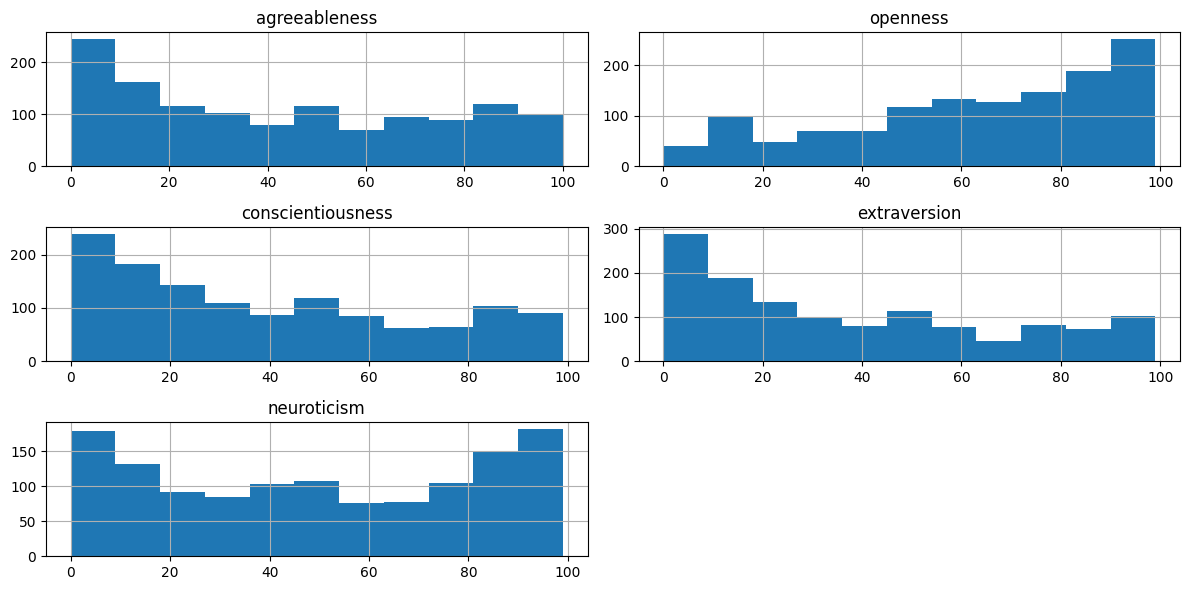

Correlacións entre trazos:
                   agreeableness  openness  conscientiousness  extraversion  \
agreeableness               1.00      0.12               0.05          0.04   
openness                    0.12      1.00              -0.05          0.22   
conscientiousness           0.05     -0.05               1.00          0.04   
extraversion                0.04      0.22               0.04          1.00   
neuroticism                 0.05     -0.00              -0.26         -0.25   

                   neuroticism  
agreeableness             0.05  
openness                 -0.00  
conscientiousness        -0.26  
extraversion             -0.25  
neuroticism               1.00  


In [8]:
print(tr[TRAITS].describe().round(1))
tr[TRAITS].hist(bins=11, figsize=(12,6)); plt.tight_layout(); plt.show()
print("Correlacións entre trazos:"); print(tr[TRAITS].corr().round(2))
n = posts.groupby(USER_COL).size()
# ESTO QUITEINO PORQUE TARDA A DIOS E A SU MADRE
# ||||||||||||||||||||||||||||||||||||||||||||||
# VVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVVV
# print("Publicacións por usuario/a:"); print(n.describe().round(1))
# print("Lonxitude media (palabras):", posts[TEXT_COL].astype(str).str.split().str.len().mean().round(1))

## 3. Agregación a nivel de usuario/a
Concatenamos as publicacións de cada usuario/a (máximo `MAX_CHARS` para limitar o custo).

In [9]:
MAX_CHARS = 20000
def clean(t):
    t = re.sub(r"http\S+", " URL ", str(t))
    return re.sub(r"\s+", " ", t).strip()

user_text = (posts.assign(_t=posts[TEXT_COL].map(clean))
                  .groupby(USER_COL)["_t"].apply(lambda s: " ".join(s)[:MAX_CHARS]))
train = tr.merge(user_text.rename("text"), left_on=USER_COL, right_index=True, how="left")
test  = te.merge(user_text.rename("text"), left_on=USER_COL, right_index=True, how="left")
print(train["text"].isna().sum(), "train sen texto;", test["text"].isna().sum(), "test sen texto")
train["text"] = train["text"].fillna(""); test["text"] = test["text"].fillna("")
Y = train[TRAITS].values
print(f"Usuarios sin texto -> Train: {train['text'].isna().sum()} | Test: {test['text'].isna().sum()}")

29 train sen texto; 10 test sen texto
Usuarios sin texto -> Train: 0 | Test: 0


## 4. Utilidades de validación (K-fold, RMSE medio)

In [10]:
def rmse_mean(y, p): return np.sqrt(((y-p)**2).mean(axis=0)).mean()
def rmse_by_trait(y, p): return dict(zip(TRAITS, np.sqrt(((y-p)**2).mean(axis=0)).round(2)))

def cv_eval(fit_predict, X, Y, k=5):
    oof = np.zeros_like(Y, dtype=float)
    for tri, vai in KFold(k, shuffle=True, random_state=SEED).split(X):
        oof[vai] = fit_predict(X[tri], Y[tri], X[vai])
    return rmse_mean(Y, oof), rmse_by_trait(Y, oof), oof

texts = train["text"].values

## 5. Baseline: predicir a media do train

In [11]:
base = lambda Xtr,Ytr,Xva: np.tile(Ytr.mean(axis=0), (len(Xva),1))
s_base, d_base, _ = cv_eval(base, texts, Y)
print("Baseline RMSE:", round(s_base,3), d_base)

Baseline RMSE: 30.308 {'agreeableness': np.float64(31.17), 'openness': np.float64(27.6), 'conscientiousness': np.float64(29.99), 'extraversion': np.float64(30.58), 'neuroticism': np.float64(32.2)}


## 6. Modelo 1: TF-IDF + Ridge
Vectorización clásica con n-gramas e regresión lineal regularizada (multi-saída).

In [12]:
def tfidf_ridge(alpha=3.0):
    def f(Xtr,Ytr,Xva):
        m = make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, max_df=0.9, ngram_range=(1,2), max_features=200000),
                          Ridge(alpha=alpha))
        m.fit(Xtr, Ytr); return np.clip(m.predict(Xva), 0, 100)
    return f
for a in [1, 3, 10, 30]:
    s, d, _ = cv_eval(tfidf_ridge(a), texts, Y)
    print(f"alpha={a:>3}  RMSE={s:.3f}  {d}")

alpha=  1  RMSE=29.688  {'agreeableness': np.float64(30.58), 'openness': np.float64(27.09), 'conscientiousness': np.float64(29.62), 'extraversion': np.float64(29.64), 'neuroticism': np.float64(31.52)}
alpha=  3  RMSE=29.891  {'agreeableness': np.float64(30.78), 'openness': np.float64(27.24), 'conscientiousness': np.float64(29.72), 'extraversion': np.float64(29.99), 'neuroticism': np.float64(31.72)}
alpha= 10  RMSE=30.116  {'agreeableness': np.float64(30.99), 'openness': np.float64(27.42), 'conscientiousness': np.float64(29.86), 'extraversion': np.float64(30.33), 'neuroticism': np.float64(31.97)}
alpha= 30  RMSE=30.232  {'agreeableness': np.float64(31.1), 'openness': np.float64(27.53), 'conscientiousness': np.float64(29.94), 'extraversion': np.float64(30.49), 'neuroticism': np.float64(32.11)}


## 7. Modelo 2: embeddings SBERT + Ridge
Codificamos fragmentos de texto con Sentence-BERT e facemos a media por usuario/a. Require `pip install sentence-transformers` (mellor con GPU/Colab).

In [13]:
!pip install sentence-transformers

In [14]:
from sentence_transformers import SentenceTransformer
sbert = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
def embed_user(u_posts, max_posts=200):
    return sbert.encode(u_posts[:max_posts], batch_size=64, normalize_embeddings=True).mean(axis=0)
users = pd.concat([train[USER_COL], test[USER_COL]]).unique()
g = posts.groupby(USER_COL)[TEXT_COL].apply(lambda s: [clean(x) for x in s])
E = {u: embed_user(g[u]) for u in users if u in g.index}
np.save("emb_sbert.npy", E, allow_pickle=True)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [15]:
# Ridge sobre embeddings (descomentar cando E estea calculado)
Etr = np.vstack([E.get(u, np.zeros(384)) for u in train[USER_COL]])
for a in [1, 10, 100]:
    f = lambda Xtr,Ytr,Xva: np.clip(Ridge(alpha=a).fit(Xtr,Ytr).predict(Xva),0,100)
    s,d,_ = cv_eval(f, Etr, Y); print(a, round(s,3), d)

1 29.746 {'agreeableness': np.float64(30.68), 'openness': np.float64(27.36), 'conscientiousness': np.float64(29.72), 'extraversion': np.float64(29.52), 'neuroticism': np.float64(31.46)}
10 30.088 {'agreeableness': np.float64(30.91), 'openness': np.float64(27.45), 'conscientiousness': np.float64(29.89), 'extraversion': np.float64(30.28), 'neuroticism': np.float64(31.9)}
100 30.275 {'agreeableness': np.float64(31.13), 'openness': np.float64(27.57), 'conscientiousness': np.float64(29.97), 'extraversion': np.float64(30.54), 'neuroticism': np.float64(32.16)}


## 8. Xeración dos CSV de envío
Formato: `team_name, variant_name, username, agreeableness, openness, conscientiousness, extraversion, neuroticism`; ficheiro `nome_equipo_nome_variante.csv`.

In [16]:
def make_submission(variant, preds):
    df = pd.DataFrame(np.clip(preds,0,100), columns=TRAITS)
    df.insert(0, "username", test[USER_COL].values)
    df.insert(0, "variant_name", variant); df.insert(0, "team_name", TEAM)
    assert len(df)==len(te) and df[TRAITS].notna().all().all()
    fn = f"{TEAM}_{variant}.csv"; df.to_csv(fn, index=False); print("Gardado", fn)
    return df

make_submission("baseline", base(texts, Y, test["text"].values))
make_submission("tfidf_ridge", tfidf_ridge(10)(texts, Y, test["text"].values))

Gardado VAIA_baseline.csv
Gardado VAIA_tfidf_ridge.csv


,team_name,variant_name,username,agreeableness,openness,conscientiousness,extraversion,neuroticism
0,VAIA,tfidf_ridge,libelle156,43.966857,62.523423,39.531692,35.941011,51.264190
1,VAIA,tfidf_ridge,drawtheApocalypse,42.491762,60.163780,40.142655,35.351901,47.629741
2,VAIA,tfidf_ridge,I_hate_kittens_,41.527535,63.889424,38.904250,36.617862,46.615730
3,VAIA,tfidf_ridge,gillybean103,43.706442,62.366440,40.901701,37.417191,50.602721
4,VAIA,tfidf_ridge,DivinePetal,41.280596,61.143253,38.808475,37.160530,49.718382
...,...,...,...,...,...,...,...,...
318,VAIA,tfidf_ridge,RetardYourAnger,43.065354,63.552946,38.184982,36.702272,49.314106
319,VAIA,tfidf_ridge,cultcrime,42.590328,63.167210,38.269074,38.799318,50.061782
320,VAIA,tfidf_ridge,y_mr_y,42.908910,62.129799,39.402927,38.892729,50.374631
321,VAIA,tfidf_ridge,nman10000,41.650854,61.592820,39.892031,35.717135,50.300955


## 9. Resultados e discusión
_(Encher: táboa comparativa de RMSE por modelo e trazo, análise de erros, que funcionou e que non, ideas futuras: filtrado de publicacións por trazo, cuestionarios con SBERT, fine-tuning, LLMs few-shot.)_